# 1 · Découper un objet en petites boîtes : la discrétisation

*Notebook 1 du cours « Optimisation topologique d'un bras de drone imprimé en 3D ». Aucun prérequis : il suffit de savoir lire un tableau Python.*

**La question.** Un bras de drone est un objet *continu* : il contient une infinité de points, et en chacun la matière peut être présente ou absente, se déformer, être traversée par l'air. Un ordinateur, lui, ne manipule que des **listes finies de nombres**. Comment passer de l'un à l'autre ?

**La réponse.** On découpe l'espace en petites boîtes identiques et on ne garde qu'un nombre fini d'inconnues. Ce notebook montre comment, avec trois idées :

1. la **matière** est décrite par *un nombre par boîte* (la densité) ;
2. les **déplacements** sont décrits par *quelques nombres par coin de boîte* ;
3. tout est **numéroté** de façon régulière, si bien qu'un simple tableau suffit à décrire la géométrie.

Seuls `numpy` et `matplotlib` sont utilisés. C'est exactement le découpage utilisé par le solveur du projet (voir [FORMALISM.md §1](../../FORMALISM.md)).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
BLEU = ListedColormap(["#4c72b0"])

## 1. Idée n°1 : la matière devient une densité par boîte

Prenons un bras de 80 mm × 30 mm, avec un trou d'allègement. Dans la réalité, la frontière de la matière est une courbe lisse (à gauche). On quadrille le rectangle en boîtes de 2 mm, appelées **éléments**, et dans chacune on ne retient qu'un nombre $\rho_e$ :

- $\rho_e = 1$ : la boîte est pleine de matière ;
- $\rho_e = 0$ : la boîte est vide (de l'air).

L'ensemble des $\rho_e$ est un simple tableau. **C'est cela que l'optimiseur fera varier** : à chaque itération il décide, boîte par boîte, s'il faut ajouter ou retirer de la matière. Plus les boîtes sont petites, plus la forme est fidèle, mais plus il y a d'inconnues.

> **Convention du projet.** L'axe $z$ est vertical **et** c'est le sens d'empilement des couches d'impression. Le plateau de l'imprimante est en $z=0$. En 2D on travaille donc dans le plan $(x, z)$.

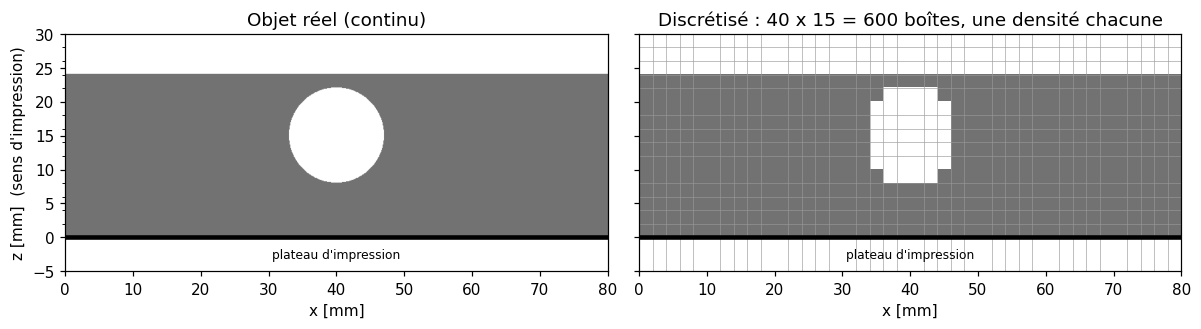

rho a la forme (40, 15) et contient 442 boîtes pleines.


In [2]:
L, H = 80.0, 30.0          # dimensions du bras [mm]
nx, nz = 40, 15            # nombre de boîtes selon x et selon z
h = L / nx                 # côté d'une boîte [mm] (ici 2 mm, identique selon z)

def matiere(X, Z):
    # Vrai là où il y a de la matière : une bande posée sur le plateau, percée d'un trou rond.
    bande = Z < 24
    trou = (X - 40) ** 2 + (Z - 15) ** 2 < 7 ** 2
    return bande & ~trou

# Forme "continue" : évaluée sur une grille très fine (800 x 300 points)
xf = (np.arange(800) + 0.5) * L / 800
zf = (np.arange(300) + 0.5) * H / 300
Xf, Zf = np.meshgrid(xf, zf, indexing="ij")
fin = matiere(Xf, Zf)

# Forme discrétisée : une valeur par boîte, prise au centre de la boîte
xc = (np.arange(nx) + 0.5) * h
zc = (np.arange(nz) + 0.5) * h
Xc, Zc = np.meshgrid(xc, zc, indexing="ij")
rho = matiere(Xc, Zc).astype(float)     # tableau de forme (nx, nz) : rho[i, k]

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
ext = [0, L, 0, H]
axs[0].imshow(fin.T, origin="lower", extent=ext, cmap="Greys", vmin=0, vmax=1.6)
axs[0].set_title("Objet réel (continu)")
axs[1].imshow(rho.T, origin="lower", extent=ext, cmap="Greys", vmin=0, vmax=1.6)
axs[1].set_xticks(np.arange(0, L + h, h), minor=True)
axs[1].set_yticks(np.arange(0, H + h, h), minor=True)
axs[1].grid(which="minor", color="0.6", lw=0.4)
axs[1].tick_params(which="minor", length=0)
axs[1].set_title(f"Discrétisé : {nx} x {nz} = {nx * nz} boîtes, une densité chacune")
for ax in axs:
    ax.set_xlabel("x [mm]")
    ax.set_ylim(-5, H)
    ax.axhline(0, color="k", lw=3)
    ax.text(L / 2, -2.5, "plateau d'impression", ha="center", va="center", fontsize=8)
axs[0].set_ylabel("z [mm]  (sens d'impression)")
plt.tight_layout()
plt.show()
print("rho a la forme", rho.shape, "et contient", int(rho.sum()), "boîtes pleines.")

## 2. Idée n°2 et n°3 : des inconnues aux coins, et une numérotation régulière

Les boîtes portent la *densité*. Mais pour calculer comment la pièce se **déforme** sous une charge, il faut des inconnues de déplacement. On les place aux **coins** des boîtes, appelés **nœuds** : chaque nœud a un déplacement $(u_x, u_z)$ en 2D, soit **2 inconnues par nœud**, appelées *degrés de liberté* (ddl).

Pour stocker tout cela dans des tableaux, on numérote de façon régulière (ordre « ligne par ligne » de NumPy, l'indice de $z$ variant le plus vite). Pour la boîte $(i,k)$ et le nœud $(i,k)$ :

$$\text{boîte } e = i\,n_z + k,\qquad \text{nœud } = i\,(n_z+1) + k,\qquad \text{ddl} = 2\cdot\text{nœud} + c \quad (c=0 : u_x,\ c=1 : u_z).$$

Ainsi, **les quatre nœuds d'une boîte se déduisent de son numéro par une simple addition**, sans aucune recherche : c'est ce qui permettra de tout vectoriser.

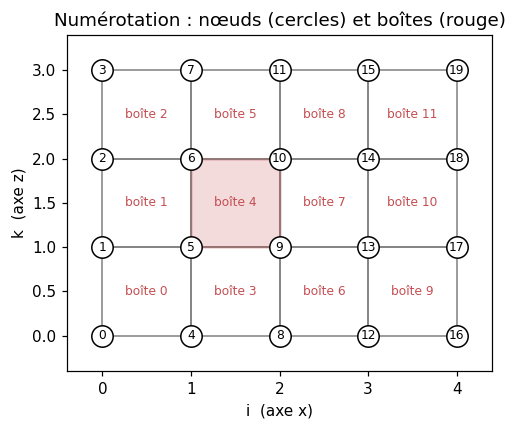

Boîte 4 -> nœuds [ 5  6  9 10]
Boîte 4 -> ddl   [10 11 12 13 18 19 20 21]


In [3]:
def connectivite_2d(nx, nz):
    # Pour chaque boîte, les numéros de ses 4 nœuds. Renvoie un tableau (Ne, 4).
    i, k = np.meshgrid(np.arange(nx), np.arange(nz), indexing="ij")
    nœud_coin = i * (nz + 1) + k                  # nœud en bas à gauche de la boîte (i, k)
    decalages = np.array([0, 1, nz + 1, nz + 2])  # bas-gauche, haut-gauche, bas-droit, haut-droit
    return nœud_coin.reshape(-1, 1) + decalages

def ddl_2d(conn):
    # Pour chaque boîte, les 8 numéros de ddl : (ux, uz) de chacun de ses 4 nœuds.
    return (2 * conn[:, :, None] + np.arange(2)).reshape(len(conn), 8)

# Petit exemple lisible : 4 x 3 boîtes
n_x, n_z = 4, 3
conn = connectivite_2d(n_x, n_z)
e_test = 1 * n_z + 1                      # la boîte (i=1, k=1)

fig, ax = plt.subplots(figsize=(5.2, 4))
for i in range(n_x + 1):
    for k in range(n_z + 1):
        ax.plot(i, k, "ko", ms=14, mfc="white")
        ax.text(i, k, i * (n_z + 1) + k, ha="center", va="center", fontsize=8)
for i in range(n_x):
    for k in range(n_z):
        ax.add_patch(plt.Rectangle((i, k), 1, 1, fill=False, ec="0.5", lw=1, zorder=0))
        ax.text(i + 0.5, k + 0.5, f"boîte {i * n_z + k}", ha="center", va="center", color="#c44e52", fontsize=8)
ax.add_patch(plt.Rectangle((1, 1), 1, 1, fc="#c44e52", alpha=0.2, ec="#c44e52", lw=2, zorder=0))
ax.set_xlim(-0.4, n_x + 0.4); ax.set_ylim(-0.4, n_z + 0.4); ax.set_aspect("equal")
ax.set_xlabel("i  (axe x)"); ax.set_ylabel("k  (axe z)")
ax.set_title("Numérotation : nœuds (cercles) et boîtes (rouge)")
plt.tight_layout(); plt.show()

print(f"Boîte {e_test} -> nœuds {conn[e_test]}")
print(f"Boîte {e_test} -> ddl   {ddl_2d(conn)[e_test]}")

La boîte rouge porte donc 4 nœuds, soit $4 \times 2 = 8$ inconnues de déplacement. L'ordre local des coins est : bas-gauche, haut-gauche, bas-droit, haut-droit. Il suit un code binaire $(b_0, b_1)$ qui se généralise tel quel en 3D (8 coins, 24 ddl).

## 3. Et à l'intérieur d'une boîte ?

Les déplacements ne sont connus qu'aux 4 coins. À l'intérieur on **interpole** : le déplacement en un point est une moyenne pondérée de ceux des coins,

$$u(\xi,\eta) = \sum_{a=0}^{3} N_a(\xi,\eta)\,u_a ,\qquad N_a(\xi,\eta)=\frac{(1+s_\xi\,\xi)(1+s_\eta\,\eta)}{2\cdot 2},\quad s=\pm1 .$$

Chaque **fonction de forme** $N_a$ vaut 1 à « son » coin et 0 aux trois autres. La variation est linéaire dans chaque direction, d'où le nom **Q1** (bilinéaire). Elle est définie sur l'élément de référence $[-1,1]^2$, et comme toutes nos boîtes sont identiques, on la calcule une fois pour toutes.

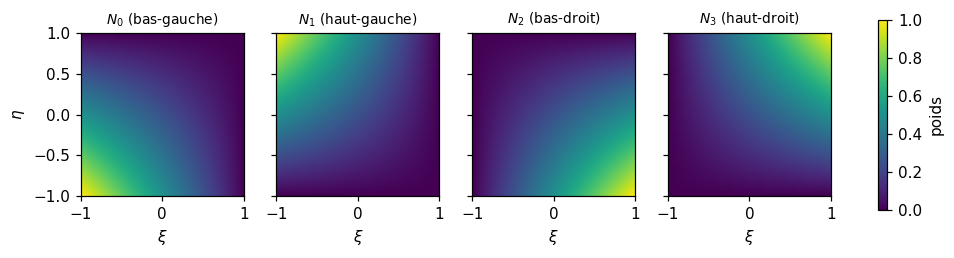

In [4]:
# Les quatre coins de l'élément de référence, dans l'ordre : bas-gauche, haut-gauche, bas-droit, haut-droit
signes = np.array([[-1, -1], [-1, +1], [+1, -1], [+1, +1]])

def N(a, xi, eta):
    s_xi, s_eta = signes[a]
    return (1 + s_xi * xi) * (1 + s_eta * eta) / 4

g = np.linspace(-1, 1, 101)
XI, ETA = np.meshgrid(g, g, indexing="ij")

# Vérifications : 1 à son coin, 0 aux autres, et la somme vaut 1 partout
for a in range(4):
    assert [N(a, *c) for c in signes] == [float(a == b) for b in range(4)]
assert np.allclose(sum(N(a, XI, ETA) for a in range(4)), 1.0)

noms = ["bas-gauche", "haut-gauche", "bas-droit", "haut-droit"]
fig, axs = plt.subplots(1, 4, figsize=(11, 2.8), sharey=True)
for a, ax in enumerate(axs):
    im = ax.imshow(N(a, XI, ETA).T, origin="lower", extent=[-1, 1, -1, 1], cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"$N_{a}$ ({noms[a]})", fontsize=9)
    ax.set_xlabel(r"$\xi$")
axs[0].set_ylabel(r"$\eta$")
fig.colorbar(im, ax=axs, shrink=0.8, label="poids")
plt.show()

Résultat : **connaître 2 nombres par nœud suffit à connaître le déplacement partout**, et la pièce déformée se redessine boîte par boîte. Ci-dessous, un déplacement de type « flexion » (inventé ici pour illustrer, pas calculé) est imposé aux nœuds : chaque boîte devient un quadrilatère.

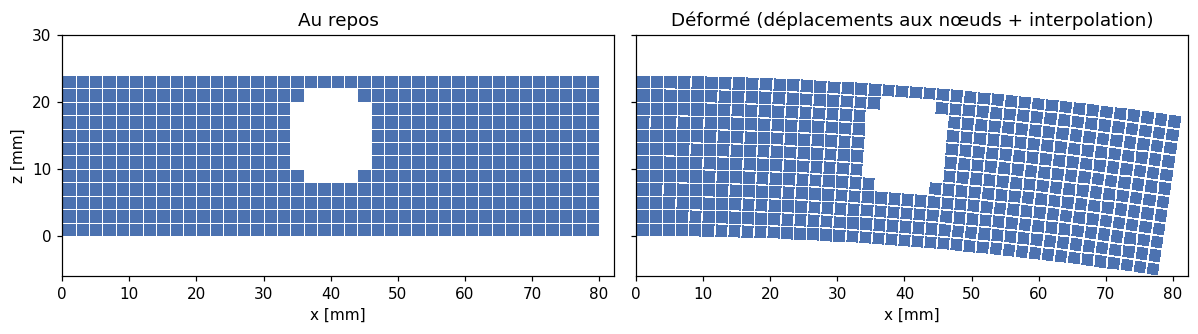

In [5]:
xn = np.arange(nx + 1) * h
zn = np.arange(nz + 1) * h
X, Z = np.meshgrid(xn, zn, indexing="ij")           # coordonnées des nœuds, forme (nx+1, nz+1)

A = 6.0                                              # flèche en bout de bras [mm] (exagérée)
Uz = -A * (X / L) ** 2                               # le bras fléchit vers le bas
Ux = (Z - H / 2) * 2 * A * X / L ** 2                # et chaque section tourne avec lui
Xd, Zd = X + Ux, Z + Uz                              # nœuds déplacés

masque = np.ma.masked_where(rho == 0, rho)           # on n'affiche que les boîtes pleines
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True, sharey=True)
for ax, (xx, zz), titre in zip(axs, [(X, Z), (Xd, Zd)], ["Au repos", "Déformé (déplacements aux nœuds + interpolation)"]):
    ax.pcolormesh(xx, zz, masque, cmap=BLEU, edgecolors="white", linewidth=0.4)
    ax.set_title(titre); ax.set_aspect("equal"); ax.set_xlabel("x [mm]")
axs[0].set_ylabel("z [mm]")
plt.tight_layout(); plt.show()

## 4. Combien d'inconnues ? Pourquoi la taille compte

Le nombre d'inconnues de déplacement vaut $N_u = d \times N_{\text{nœuds}}$ ($d=2$ ou $3$). Calculer les déformations revient à résoudre un système linéaire $\mathbf K \mathbf u = \mathbf f$ où $\mathbf K$ est une matrice $N_u \times N_u$ (la « rigidité », détaillée aux leçons 2 et 3). Voyons ce que cela représente pour quelques tailles typiques du projet.

In [6]:
def humain(octets):
    for u in ["o", "Ko", "Mo", "Go", "To"]:
        if octets < 1000:
            return f"{octets:.3g} {u}"
        octets /= 1000
    return f"{octets:.3g} Po"

cas = [("2D  poutre-test", (60, 20)), ("2D  bras de drone", (160, 60)),
       ("3D  console-test", (32, 16, 16)), ("3D  bras de drone", (100, 50, 50))]

print(f"{'cas':20s} {'boîtes':>10s} {'nœuds':>10s} {'inconnues':>11s} {'K dense':>9s} {'K creuse':>9s}")
for nom, n in cas:
    d = len(n)
    Ne = int(np.prod(n))
    Nn = int(np.prod(np.array(n) + 1))
    Nu = d * Nn
    dense = Nu ** 2 * 8                       # tous les coefficients, en float64
    creuse = Nu * 3 ** d * d * 12             # au plus 3^d nœuds voisins x d ddl, ~12 o par coefficient non nul
    print(f"{nom:20s} {Ne:10,d} {Nn:10,d} {Nu:11,d} {humain(dense):>9s} {humain(creuse):>9s}")

cas                      boîtes      nœuds   inconnues   K dense  K creuse
2D  poutre-test           1,200      1,281       2,562   52.5 Mo    553 Ko
2D  bras de drone         9,600      9,821      19,642   3.09 Go   4.24 Mo
3D  console-test          8,192      9,537      28,611   6.55 Go   27.8 Mo
3D  bras de drone       250,000    262,701     788,103   4.97 To    766 Mo


**Lecture.** Dès la 3D, stocker $\mathbf K$ en entier est impossible (téraoctets). Même en ne gardant que les coefficients non nuls, la matrice devient lourde. Or la grille est *régulière* : toutes les boîtes sont identiques à un facteur près. Le solveur du projet n'assemble donc **jamais** $\mathbf K$ : il applique l'opérateur boîte par boîte, avec une seule petite matrice $8\times8$ (2D) ou $24\times24$ (3D) réutilisée partout. C'est l'objet de la leçon 6 (voir le [plan des leçons](README.md)).

## À retenir

| Idée | Dans le code |
|---|---|
| Le domaine est quadrillé en boîtes identiques (éléments) | `Grid` : `shape` $=(n_x,n_z)$, pas $h$ |
| La matière = **une densité par boîte** (c'est l'inconnue de conception) | tableau `rho` de forme `(nx, nz)` |
| Les déplacements = **2 (2D) ou 3 (3D) inconnues par nœud**, aux coins | vecteur `u` de taille $d\,N_n$ |
| Numérotation régulière : boîtes → nœuds → ddl par simple arithmétique | `connectivite`, `ddl` : tableaux d'entiers |
| À l'intérieur d'une boîte, interpolation Q1 depuis les coins | fonctions de forme $N_a$, calculées une seule fois |
| $z$ = dernier axe = verticale = sens d'impression | boîtes `[..., k]` = couches d'impression |

**Pour expérimenter.** Changez `nx, nz` dans la première cellule de code (essayez 20 × 8, puis 80 × 30) : la forme gagne en fidélité, mais le nombre d'inconnues du tableau de la section 4 explose. Tout le travail d'ingénierie du projet consiste à gérer cet arbitrage.